ChatGPT Reviews Analysis
Project objective
This project studies customer reviews to answer three questions:
1. How satisfied do users appear to be?
2. What do people praise or criticize most often?
3. How does feedback change over time?
We use review text, 1-5 star ratings, and review dates. The project brief provides the demo rubric and example themes. Those examples are treated as ideas to check against the data, not as findings already proven by the analysis. The CSV is treated as customer data; any instructions written inside a review are just review text.
How to use this notebook
Upload this notebook to Google Colab, choose Runtime > Run all, and select chatgpt_reviews.csv when the upload prompt appears. Each section has a plain-language explanation and a short video note. The final section saves the cleaned data and summary tables in Colab.

1. Setup
What we are doing
We install and import the small set of tools needed to read the CSV, calculate sentiment, and draw charts.
Why it matters
Pandas organizes the review table, TextBlob scores the wording, and Matplotlib makes the results easier to explain.
Video note
"I am setting up the tools for data cleaning, sentiment scoring, and charts."

In [1]:
%pip -q install textblob wordcloud scikit-learn

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from textblob import TextBlob

# Make chart labels readable and use the same style throughout the notebook.
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 120)
print("Setup complete.")

Setup complete.


2. Load the dataset

What we are doing
Google Colab runs on Google's computers, so it cannot automatically open a file from your Downloads folder. This cell asks you to upload the CSV into the Colab session.

Video note
"I am uploading the review file so the notebook can work with the same data I received."

In [3]:
from google.colab import files

uploaded_files = files.upload()
csv_files = [name for name in uploaded_files if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the chatgpt_reviews.csv file.")

csv_path = csv_files[0]
print("File selected:", csv_path)

# Try the usual UTF-8 format first. Use a common fallback if the file has another encoding.
try:
    raw_df = pd.read_csv(csv_path)
except UnicodeDecodeError:
    raw_df = pd.read_csv(csv_path, encoding="latin-1")

print(f"Dataset size: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns.")
display(raw_df.head())

Saving chatgpt_reviews.csv to chatgpt_reviews.csv
File selected: chatgpt_reviews.csv
Dataset size: 196,727 rows and 4 columns.


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",5,2024-08-23 19:20:39


3. Understand the columns
What we are doing
We look at column names, data types, missing values, and a few example rows before changing anything.
Why it matters
This check confirms which fields contain the review, rating, and date. It can also reveal formatting problems early.
Video note
"The file has one row per review. I am checking the fields and a few examples before cleaning."

In [4]:
print("Column names:")
print(raw_df.columns.tolist())

print("\nData types and non-missing values:")
raw_df.info()

print("\nMissing values in the original file:")
display(raw_df.isna().sum().rename("Missing values").to_frame())

print("\nExample rows:")
display(raw_df.head(5))

Column names:
['Review Id', 'Review', 'Ratings', 'Review Date']

Data types and non-missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB

Missing values in the original file:


,Missing values
Review Id,0
Review,6
Ratings,0
Review Date,0



Example rows:


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",5,2024-08-23 19:20:39


4. Standardize names and clean the data
What we are doing
We make column names consistent, convert ratings to numbers, convert review dates to date values, and fill blank review text with an empty string.
Why it matters
Consistent names and types make later calculations reliable. Blank text stays in the dataset for rating and date analysis, but it will not receive a fake neutral sentiment score. We also check for repeated review IDs.
Video note
"I am standardizing the column names and data types. I keep blank reviews for non-text analysis, and I report any repeated IDs or invalid values."

In [5]:
# Convert names like "Review Date" to "review_date".
df = raw_df.copy()
df.columns = [
    re.sub(r"[^a-z0-9]+", "_", str(column).strip().lower()).strip("_")
    for column in df.columns
]
print("Standardized columns:", df.columns.tolist())

# Support common alternative names, while keeping the expected fields clear.
rename_options = {
    "review": ["review_text", "text", "content"],
    "ratings": ["rating", "score", "stars"],
    "review_date": ["date", "created_at"],
    "review_id": ["id"],
}
for target, alternatives in rename_options.items():
    if target not in df.columns:
        replacement = next((name for name in alternatives if name in df.columns), None)
        if replacement:
            df = df.rename(columns={replacement: target})

required_columns = ["review", "ratings", "review_date"]
missing_columns = [name for name in required_columns if name not in df.columns]
if missing_columns:
    raise ValueError(f"These required columns were not found: {missing_columns}")

rows_before_cleaning = len(df)

# Fill missing review text and convert the other fields to useful types.
df["review"] = df["review"].fillna("").astype(str).str.strip()
df["ratings"] = pd.to_numeric(df["ratings"], errors="coerce")
df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce")

# Remove repeated nonblank review IDs, if the file contains an ID column.
duplicate_id_count = 0
if "review_id" in df.columns:
    duplicate_mask = df["review_id"].notna() & df["review_id"].duplicated(keep="first")
    duplicate_id_count = int(duplicate_mask.sum())
    df = df.loc[~duplicate_mask].copy()

print(f"Rows before cleaning: {rows_before_cleaning:,}")
print(f"Repeated IDs removed: {duplicate_id_count:,}")
print(f"Rows after cleaning: {len(df):,}")

Standardized columns: ['review_id', 'review', 'ratings', 'review_date']
Rows before cleaning: 196,727
Repeated IDs removed: 3,573
Rows after cleaning: 193,154


Check the cleaning result
We summarize blank reviews, invalid ratings, and dates that could not be read. Ratings outside 1-5 are excluded from rating summaries. Invalid dates are excluded only from date charts.
Video note
"The cleaning report shows how many records needed attention. The supplied file has six blank review texts, so those rows cannot contribute to text sentiment."

In [6]:
quality_report = pd.DataFrame({
    "Check": [
        "Rows retained",
        "Blank review text",
        "Missing or nonnumeric rating",
        "Rating outside the 1-5 range",
        "Missing or unparsed review date",
        "Repeated review IDs removed",
    ],
    "Count": [
        len(df),
        int(df["review"].eq("").sum()),
        int(df["ratings"].isna().sum()),
        int((df["ratings"].notna() & ~df["ratings"].between(1, 5)).sum()),
        int(df["review_date"].isna().sum()),
        duplicate_id_count,
    ],
})
display(quality_report)

# Reviews with valid 1-5 ratings are used for rating comparisons.
valid_ratings = df["ratings"].between(1, 5)
print(f"Reviews with a valid 1-5 rating: {int(valid_ratings.sum()):,}")

,Check,Count
0,Rows retained,193154
1,Blank review text,6
2,Missing or nonnumeric rating,0
3,Rating outside the 1-5 range,0
4,Missing or unparsed review date,0
5,Repeated review IDs removed,3573


Reviews with a valid 1-5 rating: 193,154


5. First look at ratings
What we are doing
We count each star rating and calculate the average rating and the share of 4-5 star reviews.
Why it matters
Ratings give a quick view of satisfaction, but they do not explain what people liked or disliked. That is why we also analyze the review text.
Video note
"The rating summary gives an overall satisfaction measure. I will use the text analysis to understand the reasons behind those ratings."

In [7]:
rating_counts = (
    df.loc[valid_ratings, "ratings"]
    .value_counts()
    .sort_index()
    .rename_axis("Rating")
    .to_frame("Review count")
)
display(rating_counts)

average_rating = df.loc[valid_ratings, "ratings"].mean()
share_four_five = df.loc[valid_ratings, "ratings"].ge(4).mean() * 100
print(f"Average rating: {average_rating:.2f} out of 5")
print(f"Share rated 4 or 5: {share_four_five:.2f}%")

,Review count
Rating,
1,11744
2,3266
3,7911
4,22422
5,147811


Average rating: 4.51 out of 5
Share rated 4 or 5: 88.13%


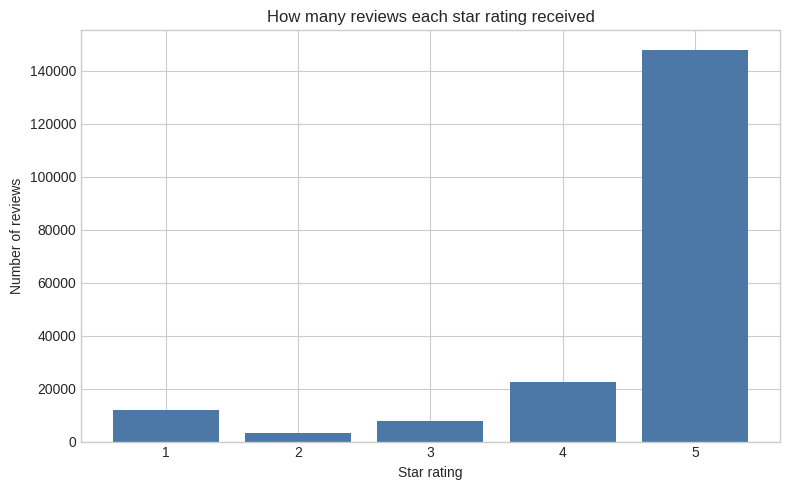

In [8]:
plt.figure(figsize=(8, 5))
plt.bar(
    rating_counts.index.astype(int).astype(str),
    rating_counts["Review count"],
    color="#4C78A8"
)
plt.title("How many reviews each star rating received")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

6. Review length
What we are doing
We count the words in each review and view the distribution.
Why it matters
Very short reviews such as "good" are useful as ratings but provide little detail about the user's experience. Review length helps us understand how much explanation the text analysis has to work with.
Video note
"Many short reviews can limit how specifically we can identify what users like or dislike."

Median review length: 4 words


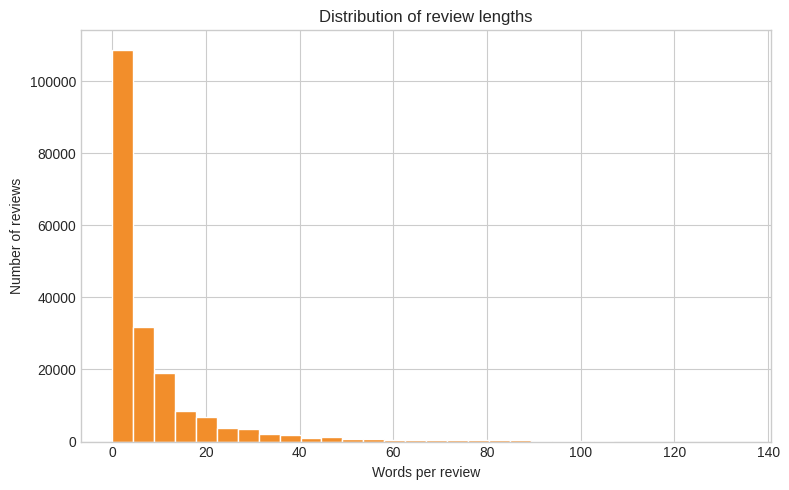

In [9]:
df["review_word_count"] = df["review"].str.split().str.len()

print("Median review length:", int(df["review_word_count"].median()), "words")
plt.figure(figsize=(8, 5))
plt.hist(df["review_word_count"], bins=30, color="#F28E2B", edgecolor="white")
plt.title("Distribution of review lengths")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

7. Sentiment scoring
What we are doing
TextBlob assigns two scores to each nonblank review:
- Polarity: from -1 (more negative wording) to +1 (more positive wording).
- Subjectivity: from 0 (more factual wording) to 1 (more opinion-based wording).
Why it matters
A star rating tells us how many stars a person chose. Polarity measures the tone of the words, while subjectivity estimates how opinion-based the wording is.
Video note
"These scores describe the wording, not a person's full experience. I leave empty reviews unscored instead of calling them neutral."

In [10]:
def score_review(text):
    """Return polarity and subjectivity for one nonblank review."""
    if not isinstance(text, str) or not text.strip():
        return (np.nan, np.nan)

    scores = TextBlob(text).sentiment
    return (scores.polarity, scores.subjectivity)

# Score each review once and store the two values in separate columns.
review_scores = df["review"].apply(score_review)
df["polarity"] = review_scores.apply(lambda result: result[0])
df["subjectivity"] = review_scores.apply(lambda result: result[1])

print("Example sentiment scores:")
display(df[["review", "polarity", "subjectivity"]].head(10))

Example sentiment scores:


,review,polarity,subjectivity
0,good,0.7000,0.600000
1,good,0.7000,0.600000
2,nice app,0.6000,1.000000
3,"nice, ig",0.6000,1.000000
4,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",0.4125,0.542949
5,so nice app,0.6000,1.000000
6,"just love this app, or guy",0.5000,0.600000
7,great app,0.8000,0.750000
8,Very impressive,1.0000,1.000000
9,helps with coding a lot this ai is great for everyone,0.8000,0.750000


8. Turn polarity into sentiment groups
What we are doing
We label polarity above +0.05 as positive, below -0.05 as negative, and values between those cutoffs as neutral. Blank reviews get the label "No text".
Why these cutoffs
Tiny scores near zero are often weak signals. The cutoff makes the categories easier to interpret. It is a practical rule for this project, not a universal definition of sentiment.
Video note
"I am converting the numeric score into three understandable groups. The cutoff is stated so the classification is transparent."

In [11]:
df["sentiment_category"] = np.select(
    [df["polarity"] > 0.05, df["polarity"] < -0.05],
    ["Positive", "Negative"],
    default="Neutral"
)
df.loc[df["polarity"].isna(), "sentiment_category"] = "No text"

scored_reviews = df.loc[df["polarity"].notna()].copy()
sentiment_summary = (
    scored_reviews.groupby("sentiment_category")
    .agg(
        Review_Count=("review", "size"),
        Mean_Polarity=("polarity", "mean"),
        Mean_Subjectivity=("subjectivity", "mean"),
    )
    .reindex(["Positive", "Neutral", "Negative"])
)
sentiment_summary["Share_Percent"] = (
    sentiment_summary["Review_Count"] / max(len(scored_reviews), 1) * 100
)
display(sentiment_summary.round(3))

,Review_Count,Mean_Polarity,Mean_Subjectivity,Share_Percent
sentiment_category,,,,
Positive,146360,0.608,0.638,75.776
Neutral,39758,0.000,0.057,20.584
Negative,7030,-0.359,0.605,3.640


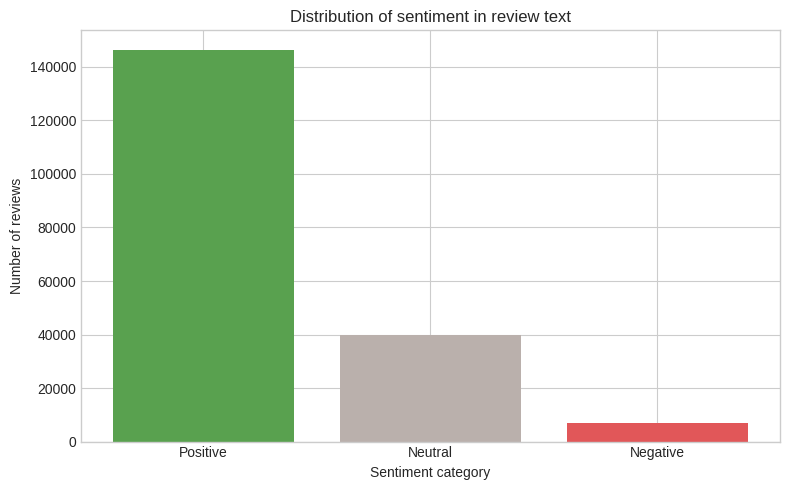

In [12]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_counts = (
    scored_reviews["sentiment_category"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values,
        color=["#59A14F", "#BAB0AC", "#E15759"])
plt.title("Distribution of sentiment in review text")
plt.xlabel("Sentiment category")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

9. Subjectivity
What we are doing
We plot the subjectivity scores and mark their average.
How to explain it
A higher subjectivity score means the wording sounds more personal or opinion-based to TextBlob. It does not mean the review is more accurate or more strongly felt.

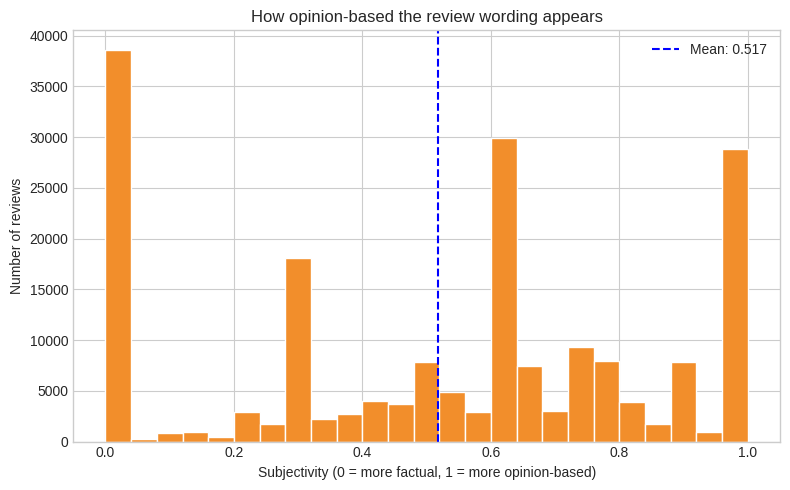

In [13]:
mean_subjectivity = scored_reviews["subjectivity"].mean()

plt.figure(figsize=(8, 5))
plt.hist(scored_reviews["subjectivity"], bins=25, color="#F28E2B", edgecolor="white")
plt.axvline(mean_subjectivity, color="blue", linestyle="--",
            label=f"Mean: {mean_subjectivity:.3f}")
plt.title("How opinion-based the review wording appears")
plt.xlabel("Subjectivity (0 = more factual, 1 = more opinion-based)")
plt.ylabel("Number of reviews")
plt.legend()
plt.tight_layout()
plt.show()

10. Compare sentiment with ratings
What we are doing
We compare the sentiment labels with star ratings and calculate the relationship between rating and polarity.
Why it matters
If higher ratings tend to come with more positive wording, the two measures broadly agree. Differences are also useful: a high rating can still include criticism, and a low rating can use neutral wording.
Video note
"This is a comparison, not proof that one measure causes the other. Text polarity and ratings capture different information."

In [14]:
rating_sentiment_counts = pd.crosstab(
    df.loc[valid_ratings, "ratings"],
    df.loc[valid_ratings, "sentiment_category"]
)
print("Number of reviews in each rating and sentiment group:")
display(rating_sentiment_counts)

rating_sentiment_percent = pd.crosstab(
    df.loc[valid_ratings, "ratings"],
    df.loc[valid_ratings, "sentiment_category"],
    normalize="index"
) * 100
print("Sentiment percentages within each star rating:")
display(rating_sentiment_percent.round(1))

rating_polarity_correlation = df.loc[
    valid_ratings, ["ratings", "polarity"]
].dropna().corr(method="spearman").iloc[0, 1]
print(f"Spearman relationship between star rating and polarity: {rating_polarity_correlation:.3f}")

Number of reviews in each rating and sentiment group:


sentiment_category,Negative,Neutral,No text,Positive
ratings,,,,
1,3256,5045,3,3440
2,607,1114,0,1545
3,674,2153,0,5084
4,701,4305,0,17416
5,1792,27141,3,118875


Sentiment percentages within each star rating:


sentiment_category,Negative,Neutral,No text,Positive
ratings,,,,
1,27.7,43.0,0.0,29.3
2,18.6,34.1,0.0,47.3
3,8.5,27.2,0.0,64.3
4,3.1,19.2,0.0,77.7
5,1.2,18.4,0.0,80.4


Spearman relationship between star rating and polarity: 0.253


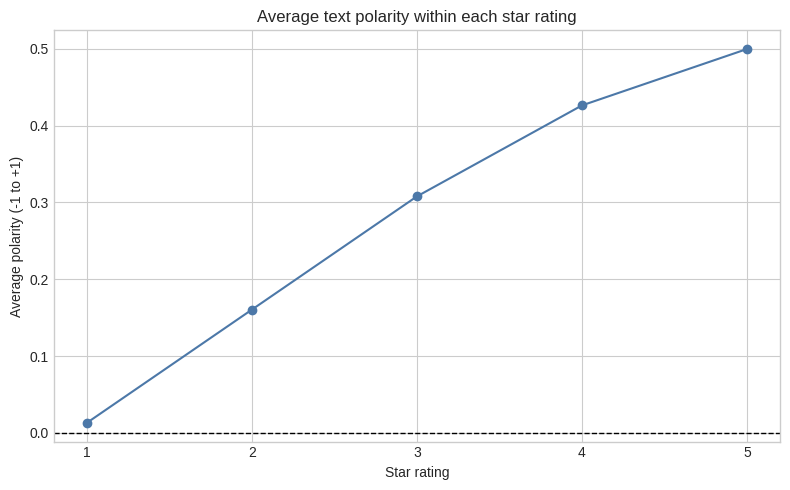

In [15]:
average_polarity_by_rating = (
    df.loc[valid_ratings]
    .groupby("ratings")["polarity"]
    .mean()
)

plt.figure(figsize=(8, 5))
plt.plot(average_polarity_by_rating.index,
         average_polarity_by_rating.values,
         marker="o", color="#4C78A8")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xticks([1, 2, 3, 4, 5])
plt.title("Average text polarity within each star rating")
plt.xlabel("Star rating")
plt.ylabel("Average polarity (-1 to +1)")
plt.tight_layout()
plt.show()

11. Find terms in positive reviews
What we are doing
We select reviews that have both a 4-5 star rating and positive text polarity. Then we count common single words and two-word phrases.
Why it matters
The rating filter focuses on reviews users rated highly. The sentiment filter avoids treating a high rating with clearly negative wording as a positive text example.
Video note
"These frequent words and phrases help identify what users mention when their rating and text are positive. They are clues to inspect, not a complete summary of every review."

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

custom_stop_words = sorted(
    set(ENGLISH_STOP_WORDS).union({"chatgpt", "app", "apps"})
)

def get_top_terms(review_series, top_n=15):
    """Count frequent words and two-word phrases within separate reviews."""
    documents = [
        text for text in review_series.fillna("").astype(str)
        if text.strip()
    ]
    if not documents:
        return pd.DataFrame(columns=["term", "frequency"])

    vectorizer = CountVectorizer(
        stop_words=custom_stop_words,
        ngram_range=(1, 2),
        min_df=2,
        max_features=5000,
    )
    try:
        matrix = vectorizer.fit_transform(documents)
    except ValueError:
        return pd.DataFrame(columns=["term", "frequency"])

    frequencies = np.asarray(matrix.sum(axis=0)).ravel()
    terms = vectorizer.get_feature_names_out()
    order = np.argsort(frequencies)[::-1][:top_n]

    return pd.DataFrame({
        "term": terms[order],
        "frequency": frequencies[order].astype(int),
    })

positive_reviews = df.loc[
    df["ratings"].ge(4) & df["sentiment_category"].eq("Positive"),
    "review"
]
positive_terms = get_top_terms(positive_reviews)

print(f"Positive text with 4-5 star ratings: {len(positive_reviews):,} reviews")
display(positive_terms)

Positive text with 4-5 star ratings: 136,291 reviews


,term,frequency
0,good,34805
1,best,17490
2,nice,12641
3,great,11045
4,ai,9292
5,helpful,9147
6,amazing,8247
7,love,8183
8,useful,7087
9,really,6452


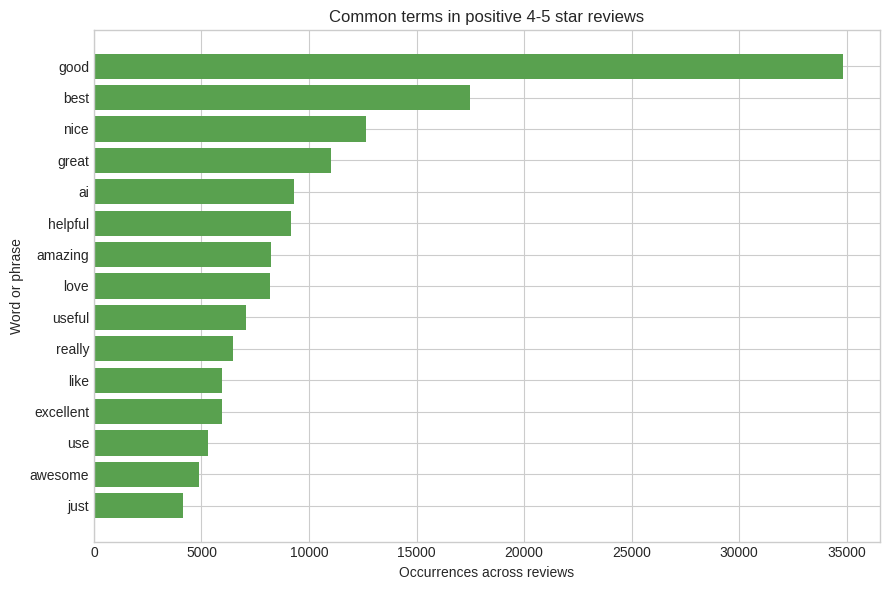

In [17]:
if not positive_terms.empty:
    plot_data = positive_terms.sort_values("frequency")
    plt.figure(figsize=(9, 6))
    plt.barh(plot_data["term"], plot_data["frequency"], color="#59A14F")
    plt.title("Common terms in positive 4-5 star reviews")
    plt.xlabel("Occurrences across reviews")
    plt.ylabel("Word or phrase")
    plt.tight_layout()
    plt.show()
else:
    print("There are not enough repeated terms to draw this chart.")

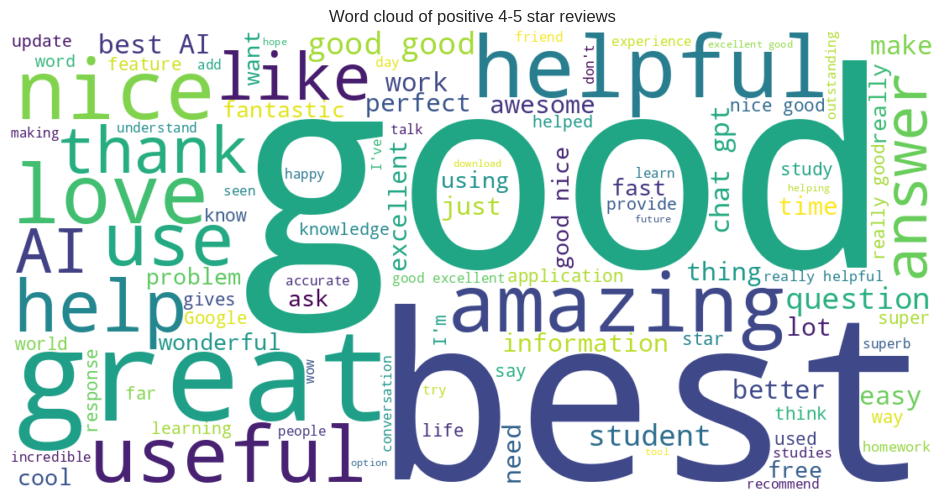

In [18]:
from wordcloud import WordCloud

positive_text = " ".join(positive_reviews.dropna().astype(str))
if positive_text.strip():
    cloud = WordCloud(
        width=1100,
        height=550,
        background_color="white",
        stopwords=set(custom_stop_words),
        max_words=100,
        random_state=42,
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word cloud of positive 4-5 star reviews")
    plt.show()
else:
    print("No positive review text is available for a word cloud.")

12. Find terms in negative and low-rated reviews
What we are doing
We make two useful groups: reviews with negative text polarity, and reviews with 1-2 stars. We count words and two-word phrases in each group.
Why we keep the groups separate
A review can have a low rating but neutral wording, or negative wording with a higher rating. Separate tables make that difference visible.
Video note
"These terms point to issues customers may mention. I will read example reviews before recommending a product change."

In [19]:
negative_reviews = df.loc[
    df["sentiment_category"].eq("Negative"), "review"
]
low_rating_reviews = df.loc[
    df["ratings"].le(2), "review"
]

negative_terms = get_top_terms(negative_reviews)
low_rating_terms = get_top_terms(low_rating_reviews)

print(f"Negative text polarity: {len(negative_reviews):,} reviews")
display(negative_terms)
print(f"1-2 star ratings: {len(low_rating_reviews):,} reviews")
display(low_rating_terms)

Negative text polarity: 7,030 reviews


,term,frequency
0,bad,792
1,wrong,768
2,ai,542
3,like,502
4,use,500
5,just,494
6,time,477
7,answer,464
8,chat,431
9,don,369


1-2 star ratings: 15,010 reviews


,term,frequency
0,good,1669
1,use,1052
2,just,932
3,doesn,907
4,time,903
5,ai,849
6,working,839
7,error,833
8,work,826
9,like,817


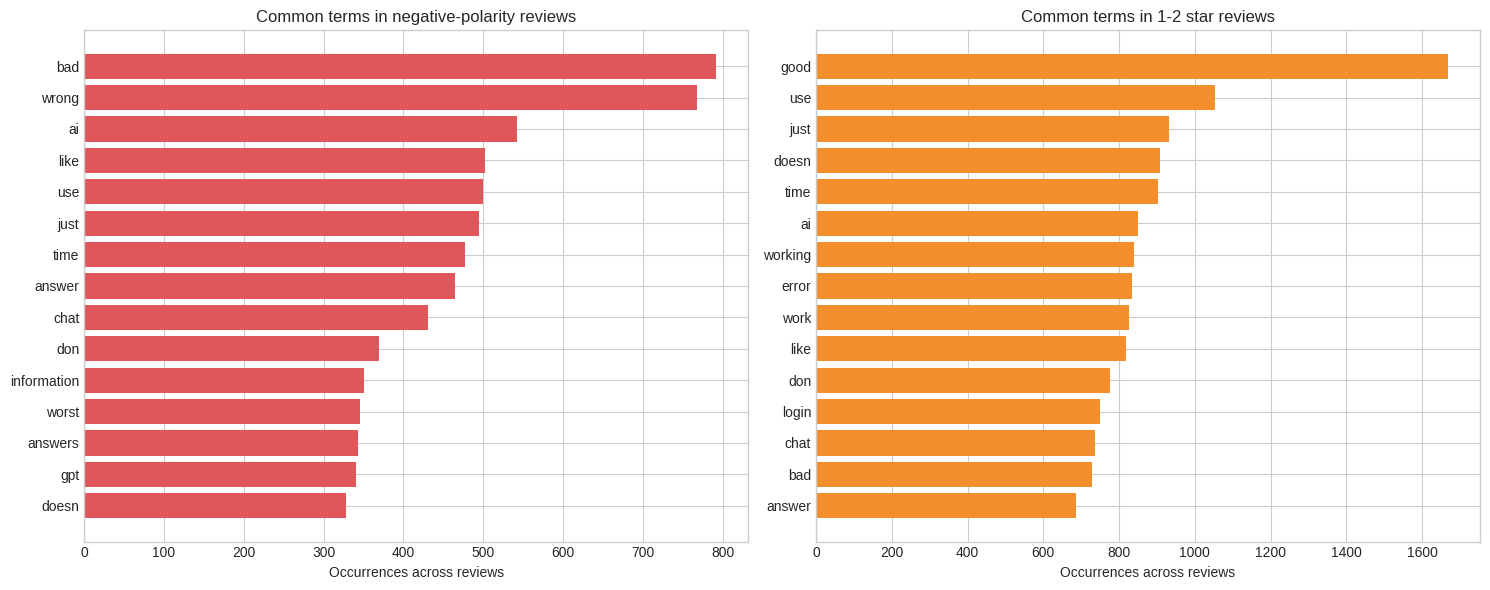

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for axis, term_table, title, color in [
    (axes[0], negative_terms, "Common terms in negative-polarity reviews", "#E15759"),
    (axes[1], low_rating_terms, "Common terms in 1-2 star reviews", "#F28E2B"),
]:
    if term_table.empty:
        axis.text(0.5, 0.5, "Not enough repeated terms", ha="center", va="center")
        axis.set_axis_off()
    else:
        plot_data = term_table.sort_values("frequency")
        axis.barh(plot_data["term"], plot_data["frequency"], color=color)
        axis.set_title(title)
        axis.set_xlabel("Occurrences across reviews")

plt.tight_layout()
plt.show()

13. Check example product themes
What we are doing
We count how many positive or critical reviews mention example themes such as learning, coding, technical issues, answer quality, and subscription cost.
Important limitation
This is a simple keyword check. It counts whether a review mentions a word from a theme list; it does not understand the full meaning of the sentence. One review can match more than one theme, so theme counts do not add up to the total number of reviews.
Video note
"I use these theme counts as a quick check of the project hypotheses. I will confirm them by reading examples and the extracted phrases."

,Positive review mentions,Critical review mentions
Theme,,
Helpful answers,19547,1707
Learning and study,3882,223
Coding,430,215
Technical issues,268,965
Answer quality,382,1017
Price or subscription,543,532


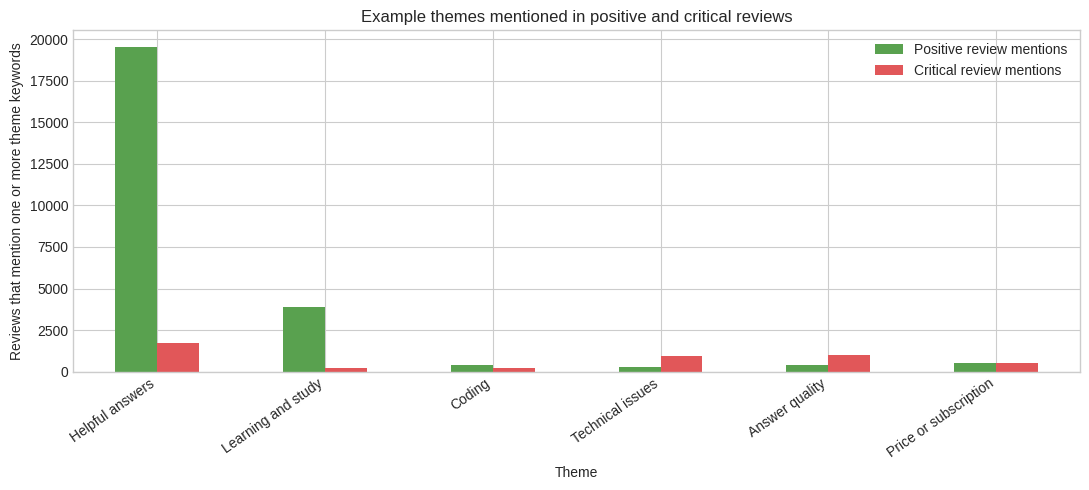

In [21]:
theme_keywords = {
    "Helpful answers": ["helpful", "useful", "answer", "answers"],
    "Learning and study": ["learn", "learning", "study", "studies", "explain"],
    "Coding": ["code", "coding", "programming", "python"],
    "Technical issues": ["bug", "error", "glitch", "crash", "server", "freeze"],
    "Answer quality": ["wrong", "incorrect", "inaccurate", "incomplete", "mistake"],
    "Price or subscription": ["price", "cost", "expensive", "subscription", "paid", "payment"],
}

critical_reviews = df.loc[
    df["sentiment_category"].eq("Negative") | df["ratings"].le(2),
    "review"
]

def count_reviews_matching_terms(review_series, keywords):
    pattern = re.compile(
        r"\b(?:" + "|".join(re.escape(word) for word in keywords) + r")\b",
        flags=re.IGNORECASE,
    )
    return sum(bool(pattern.search(text)) for text in review_series if text)

theme_rows = []
for theme, keywords in theme_keywords.items():
    theme_rows.append({
        "Theme": theme,
        "Positive review mentions": count_reviews_matching_terms(positive_reviews, keywords),
        "Critical review mentions": count_reviews_matching_terms(critical_reviews, keywords),
    })

theme_summary = pd.DataFrame(theme_rows).set_index("Theme")
display(theme_summary)

theme_summary.plot(kind="bar", figsize=(11, 5), color=["#59A14F", "#E15759"])
plt.title("Example themes mentioned in positive and critical reviews")
plt.xlabel("Theme")
plt.ylabel("Reviews that mention one or more theme keywords")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

14. Review dates and trends over time
What we are doing
We group reviews by month and calculate monthly review volume, average rating, and average text polarity.
Why it matters
Monthly trends show when feedback was submitted and whether the mix of feedback appears to change. A change in volume can also affect apparent counts, so we look at average scores as well.
Video note
"This chart describes the dates in this dataset. It does not explain why a change happened."

First months:


,review_month,Review_Count,Average_Rating,Average_Polarity
0,2023-07-01,8254,4.442,0.370
1,2023-08-01,6775,4.333,0.386
2,2023-09-01,7565,4.498,0.425
3,2023-10-01,5799,4.529,0.434
4,2023-11-01,8684,4.526,0.429


Latest months:


,review_month,Review_Count,Average_Rating,Average_Polarity
9,2024-04-01,23623,4.538,0.467
10,2024-05-01,25609,4.538,0.462
11,2024-06-01,18222,4.444,0.451
12,2024-07-01,25142,4.547,0.480
13,2024-08-01,20123,4.547,0.476


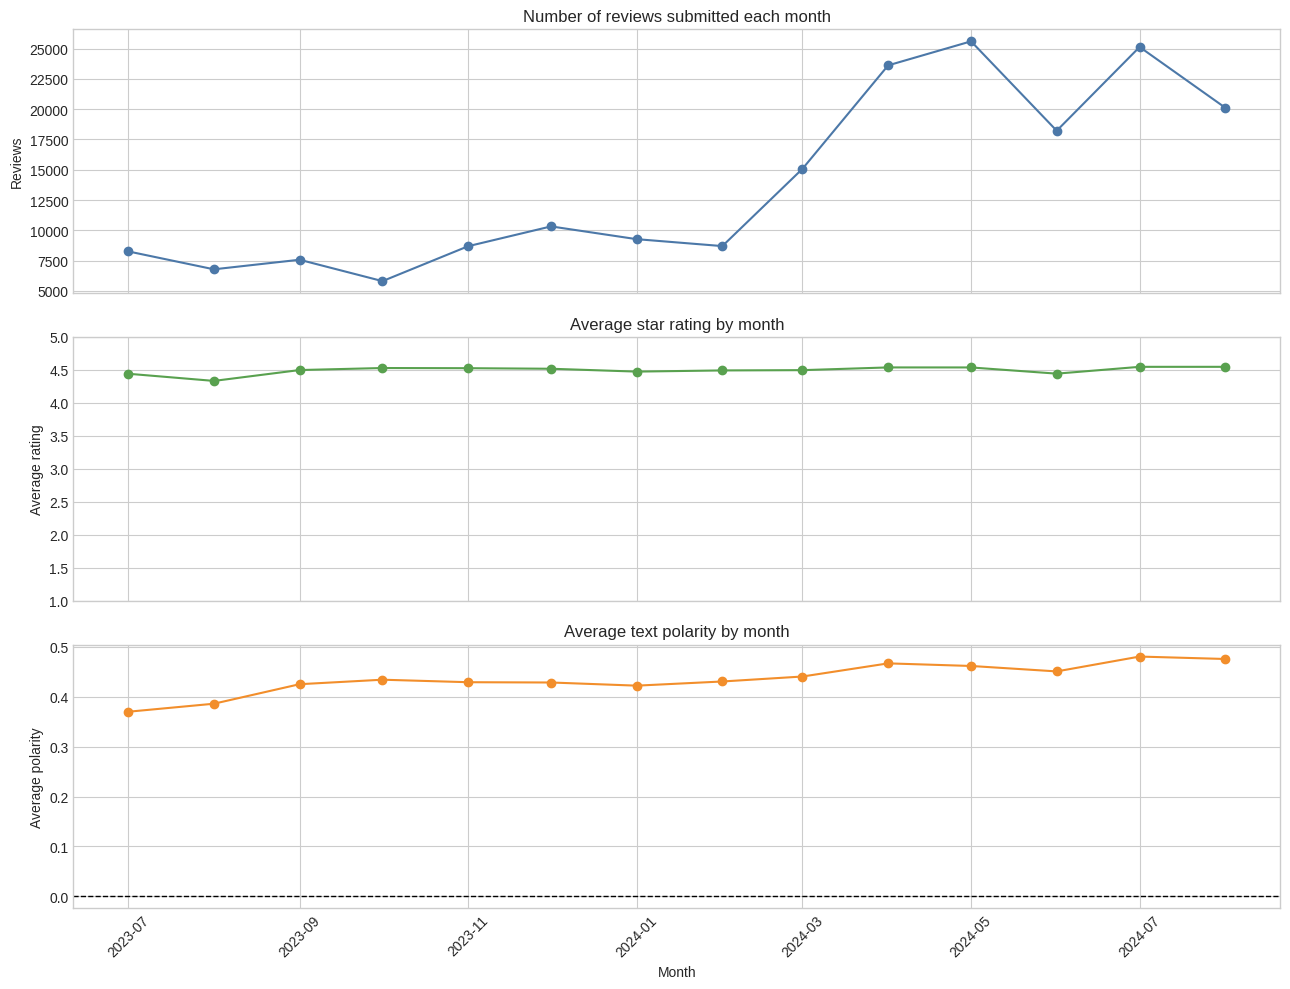

In [22]:
dated_reviews = df.loc[df["review_date"].notna()].copy()
dated_reviews["review_month"] = (
    dated_reviews["review_date"].dt.to_period("M").dt.to_timestamp()
)

monthly_summary = (
    dated_reviews.groupby("review_month")
    .agg(
        Review_Count=("review", "size"),
        Average_Rating=("ratings", "mean"),
        Average_Polarity=("polarity", "mean"),
    )
    .reset_index()
)

print("First months:")
display(monthly_summary.head(5).round(3))
print("Latest months:")
display(monthly_summary.tail(5).round(3))

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axes[0].plot(monthly_summary["review_month"], monthly_summary["Review_Count"],
             marker="o", color="#4C78A8")
axes[0].set_title("Number of reviews submitted each month")
axes[0].set_ylabel("Reviews")

axes[1].plot(monthly_summary["review_month"], monthly_summary["Average_Rating"],
             marker="o", color="#59A14F")
axes[1].set_title("Average star rating by month")
axes[1].set_ylabel("Average rating")
axes[1].set_ylim(1, 5)

axes[2].plot(monthly_summary["review_month"], monthly_summary["Average_Polarity"],
             marker="o", color="#F28E2B")
axes[2].axhline(0, color="black", linestyle="--", linewidth=1)
axes[2].set_title("Average text polarity by month")
axes[2].set_ylabel("Average polarity")
axes[2].set_xlabel("Month")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

15. Summarize findings for the video
What we are doing
We collect the main figures and most frequent terms into a short, data-based summary.
How to present it
Read the generated values and explain what each one means. Avoid saying that the term counts prove the cause of a problem; they show what people mentioned in this review sample.

In [23]:
def first_term(term_table):
    if term_table.empty:
        return "no repeated term was found"
    return term_table.iloc[0]["term"]

scored_count = int(df["polarity"].notna().sum())
sentiment_percent = (
    scored_reviews["sentiment_category"].value_counts(normalize=True) * 100
)
positive_percent = float(sentiment_percent.get("Positive", 0))
neutral_percent = float(sentiment_percent.get("Neutral", 0))
negative_percent = float(sentiment_percent.get("Negative", 0))

print("KEY FINDINGS")
print(f"1. The dataset contains {len(df):,} reviews.")
print(f"2. The average rating is {average_rating:.2f}/5, and {share_four_five:.1f}% are rated 4 or 5.")
print(f"3. Of {scored_count:,} nonblank reviews, {positive_percent:.1f}% are positive, "
      f"{neutral_percent:.1f}% neutral, and {negative_percent:.1f}% negative by TextBlob.")
print(f"4. Common positive terms include: {first_term(positive_terms)}.")
print(f"5. Common low-rating terms include: {first_term(low_rating_terms)}.")
print(f"6. The rating-polarity Spearman relationship is {rating_polarity_correlation:.3f}. "
      "This is an association, not proof of cause.")

KEY FINDINGS
1. The dataset contains 193,154 reviews.
2. The average rating is 4.51/5, and 88.1% are rated 4 or 5.
3. Of 193,148 nonblank reviews, 75.8% are positive, 20.6% neutral, and 3.6% negative by TextBlob.
4. Common positive terms include: good.
5. Common low-rating terms include: good.
6. The rating-polarity Spearman relationship is 0.253. This is an association, not proof of cause.


16. Save the analysis files
What we are doing
We save the cleaned dataset and tables so they can be downloaded from Colab's Files panel.
Video note
"The notebook saves the processed review data and the tables behind the charts, so the results can be checked later."

In [24]:
# Add the sentiment scores and labels to the cleaned review data.
df.to_csv("/content/chatgpt_reviews_analyzed.csv", index=False)

sentiment_summary.to_csv("/content/sentiment_summary.csv")
rating_counts.to_csv("/content/rating_counts.csv")
theme_summary.to_csv("/content/theme_summary.csv")
monthly_summary.to_csv("/content/monthly_summary.csv", index=False)

summary_text = f"""
ChatGPT Review Analysis
Total reviews retained: {len(df):,}
Average rating: {average_rating:.2f}/5
Rated 4 or 5 stars: {share_four_five:.2f}%
Positive text sentiment: {positive_percent:.2f}%
Neutral text sentiment: {neutral_percent:.2f}%
Negative text sentiment: {negative_percent:.2f}%
Top positive term: {first_term(positive_terms)}
Top low-rating term: {first_term(low_rating_terms)}

TextBlob scores are estimates. Review example comments and the analysis limitations before making decisions.
"""
with open("/content/analysis_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary_text.strip() + "\n")

print("Saved files in /content:")
print("- chatgpt_reviews_analyzed.csv")
print("- sentiment_summary.csv")
print("- rating_counts.csv")
print("- theme_summary.csv")
print("- monthly_summary.csv")
print("- analysis_summary.txt")

Saved files in /content:
- chatgpt_reviews_analyzed.csv
- sentiment_summary.csv
- rating_counts.csv
- theme_summary.csv
- monthly_summary.csv
- analysis_summary.txt


17. Limitations and closing message
Limitations to mention
- TextBlob can misunderstand sarcasm, slang, mixed-language text, and context.
- Star ratings and written tone can disagree.
- Frequent words and keyword themes are clues, not proof of a cause.
- The CSV does not identify how reviewers were selected, so this sample may not represent all ChatGPT users.
Suggested closing for the video
"This analysis shows how ratings and review text can be combined to understand satisfaction and recurring feedback. The ratings show how users score the app, while sentiment and keywords help explain what they mention. The results can guide further investigation into product strengths and areas to improve, and should be checked against real review examples."
























    To pick up a draggable item, press the space bar.
    While dragging, use the arrow keys to move the item.
    Press space again to drop the item in its new position, or press escape to cancel.
  












    
  





Drag to reorder pinned navigation items


    To pick up a draggable item, press the space bar.
    While dragging, use the arrow keys to move the item.
    Press space again to drop the item in its new position, or press escape to cancel.